# TuniShop — 03. EDA Clients : achat, profil, fidélité, géographie, satisfaction

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

**Objectif :** connaître les clients : combien de fois ils achètent, ce qui fait leur valeur, s'ils reviennent, où ils sont et ce qu'ils pensent.

| N° (Plan_Analyse_EDA) | Question |
|---|---|
| Q5 | Combien de fois les clients achètent-ils ? D'où viennent les clients de l'année ? |
| Q6 | Le profil du client (type, âge, canal d'inscription) change-t-il sa valeur ? |
| Q7 | Les clients reviennent-ils ? (analyse de cohortes) |
| Q8 | Où sont les clients ? |
| Q15 | Le retard dégrade-t-il la satisfaction ? |
| Q18 | Que disent les avis ? |

Pour chaque question : un tableau rappelle l'**hypothèse** du plan d'analyse, les **vues** utilisées et la **méthode** ; puis viennent le calcul (cellules **🔗 SQL direct** exécutées par SQL Server, et pandas), le graphique, la **lecture** et le **verdict** de l'hypothèse (✅ confirmée, 🟡 nuancée, ❌ infirmée).

Les figures sont enregistrées dans `06_Exports/Figures` et les tableaux de résultats dans `06_Exports/Tables` : ils alimentent les rapports de `04_Livrables/EDA`.

## 0. Connexion au DWH et chargement

Le notebook lit les 23 vues `bi.v_*` **en direct** dans SQL Server (réglages dans `00_Commun/tunishop_analytics/config.py`), puis vérifie qu'il s'agit bien du DWH validé.

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

In [2]:
chargement.ouvrir_connexion()
vues, p = chargement.charger_donnees(source="dwh")

# Raccourcis vers les tables préparées
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 13/11/2026 23:41
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes


  v_fact_remboursements             8 815 lignes
  v_fact_avis                       9 314 lignes
  v_fact_marketing_quotidien        3 427 lignes


  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [3]:
# Point de départ contrôlé : 5 totaux, valeur validée (PV) = calcul SQL = calcul Python ? (attendu : OK partout)
validation.verifier_coherence(p)

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


### Q5. Combien de fois les clients achètent-ils ? D'où viennent les clients de l'année ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | La plupart des clients achètent peu ; une grande part des clients de l'année sont nouveaux. |
| **Indicateurs** | Commandes par client, distribution des montants, part de nouveaux clients par an |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_client` |
| **Méthode** | pandas |
| **Visualisation** | Histogrammes (échelle log pour les montants) |
| **Lien data mining / ML** | Churn et RFM : fréquence, montant |

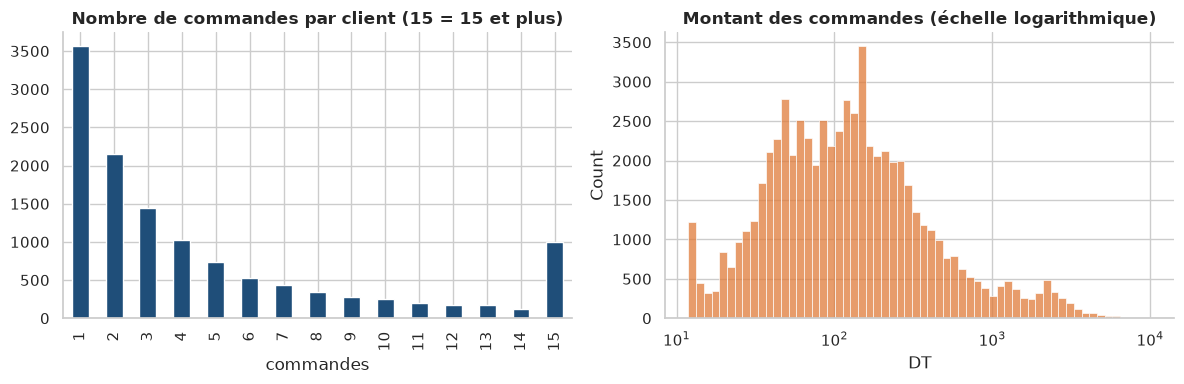

,count,mean,std,min,50%,75%,90%,99%,max
commandes,12 411.000,5.232,6.534,1.000,3.000,6.000,13.000,32.000,91.000
ca,12 411.000,1 446.577,2 837.759,11.900,450.780,1 415.920,3 816.000,14 113.583,46 589.000


,clients,nouveaux,part_nouveaux
annee,,,
2023,4014,4014,1.000
2024,5520,3643,0.660
2025,7365,4754,0.645


In [4]:
achats = features.commandes_achats(p)                      # hors échec de paiement et client inconnu
par_client = achats.groupby("client_sk").agg(commandes=("commande_id", "count"), ca=("montant_total_ttc", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
par_client["commandes"].clip(upper=15).value_counts().sort_index().plot.bar(ax=axes[0], color=cfg.BLEU)
axes[0].set_title("Nombre de commandes par client (15 = 15 et plus)"); axes[0].set_xlabel("commandes")
sns.histplot(achats["montant_total_ttc"], bins=60, log_scale=True, ax=axes[1], color=cfg.ORANGE)
axes[1].set_title("Montant des commandes (échelle logarithmique)"); axes[1].set_xlabel("DT")
plt.tight_layout(); montrer("Q05_1")

# Nouveaux clients et clients récurrents par année
premiere = achats.groupby("client_sk")["date"].min().dt.year
achats["annee_premiere"] = achats["client_sk"].map(premiere)
achats["annee"] = achats["annee"].astype(int)
clients_an = achats.groupby("annee").apply(lambda x: pd.Series({
    "clients": x["client_sk"].nunique(),
    "nouveaux": x.loc[x["annee_premiere"] == x.name, "client_sk"].nunique()}), include_groups=False)
clients_an["part_nouveaux"] = clients_an["nouveaux"] / clients_an["clients"]
display(par_client.describe(percentiles=[.5, .75, .9, .99]).T)
clients_an

In [5]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(clients_an, "Q05_nouveaux_clients")
print("Tableaux exportés.")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.eda_q05_nouveaux_clients                      3 lignes
Tableaux exportés.


> **Lecture.** 12 411 clients ont acheté. La moitié a passé 3 commandes ou moins, et 10 % en ont passé 13 ou plus. Le CA par client est très concentré : médiane 451 DT, moyenne 1 447 DT. Le montant des commandes est très asymétrique, d'où l'échelle logarithmique. Surtout, **66 % des clients de 2024 et 64,5 % de ceux de 2025 sont nouveaux** : la base se renouvelle beaucoup, ce qui fait de la fidélisation, donc du churn, un vrai enjeu. **Pour le ML :** les variables de montant devront être transformées (logarithme) ou traitées par des modèles d'arbres.

> ✅ **Verdict : hypothèse confirmée** — la moitié des clients a 3 commandes ou moins ; 64 à 66 % des clients de l'année sont nouveaux.

### Q6. Le profil du client (type, âge, canal d'inscription) change-t-il sa valeur ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Le type de client et le canal d'inscription influencent la valeur ; l'âge influence peu. |
| **Indicateurs** | Clients, CA reconnu, CA par client, commandes par client par attribut |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_client`, `v_dim_statut_commande` |
| **Méthode** | SQL direct |
| **Visualisation** | Barres par tranche et par canal |
| **Lien data mining / ML** | Churn : variables de profil |

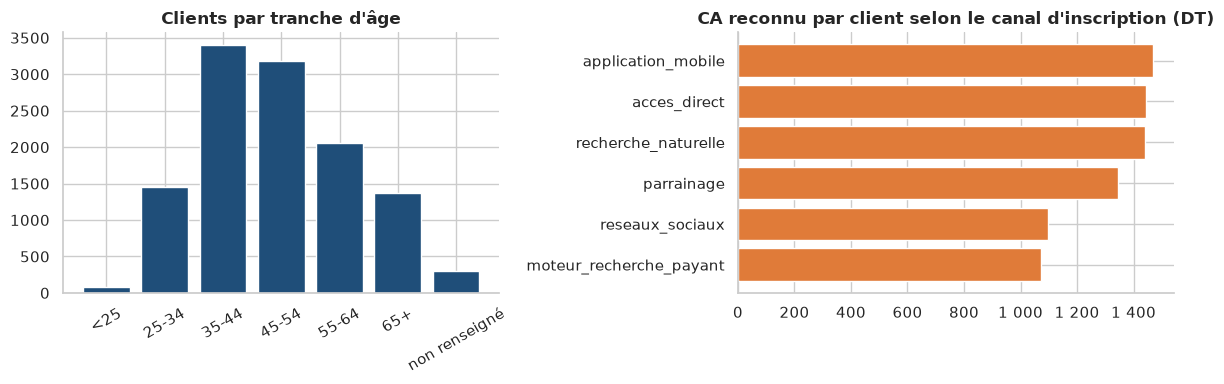

,clients,ca_reconnu_ttc,ca_par_client,commandes_par_client
type_client,,,,
professionnel,267,1 551 228.255,5 809.844,7.873
particulier,11588,13 983 116.020,1 206.689,4.889


,clients,ca_reconnu_ttc,ca_par_client,commandes_par_client
tranche_age,,,,
<25,85,112 062.990,1 318.388,4.612
25-34,1458,1 776 233.890,1 218.267,4.918
35-44,3405,4 172 986.065,1 225.547,5.041
45-54,3181,3 753 036.775,1 179.829,4.803
55-64,2061,2 435 103.455,1 181.516,4.786
65+,1371,1 721 623.730,1 255.743,4.893
non renseigné,294,1 563 297.370,5 317.338,7.408


,clients,ca_reconnu_ttc,ca_par_client,commandes_par_client
canal_inscription,,,,
moteur_recherche_payant,724,775 409.025,1 071.007,4.613
reseaux_sociaux,3645,4 000 661.070,1 097.575,4.247
parrainage,885,1 191 420.475,1 346.238,5.269
recherche_naturelle,2219,3 196 021.320,1 440.298,5.452
acces_direct,2666,3 848 941.665,1 443.714,5.260
application_mobile,1716,2 521 890.720,1 469.633,5.332


In [6]:
# 🔗 SQL direct — clients, CA reconnu et CA par client selon la tranche d'âge et le canal d'inscription.
# On compte les clients avec COUNT(DISTINCT client_id) (l'identifiant métier), pas client_sk :
# si un client avait plusieurs versions (historique SCD2), client_sk le compterait plusieurs fois.
# COALESCE remplace une valeur vide (NULL) par « non renseigné » pour qu'elle apparaisse comme un groupe.
def valeur_client_par(attribut):
    return sql(f"""
        SELECT COALESCE(cl.{attribut}, 'non renseigné')                    AS {attribut},
               COUNT(DISTINCT cl.client_id)                               AS clients,
               SUM(c.montant_total_ttc)                                   AS ca_reconnu_ttc,
               SUM(c.montant_total_ttc) / COUNT(DISTINCT cl.client_id)     AS ca_par_client,
               1.0 * COUNT(*) / COUNT(DISTINCT cl.client_id)               AS commandes_par_client
        FROM bi.v_fact_commandes c
        JOIN bi.v_dim_client cl          ON cl.client_sk = c.client_sk
        JOIN bi.v_dim_statut_commande s  ON s.statut_commande_sk = c.statut_commande_sk
        WHERE s.famille_statut = 'aboutie' AND c.client_sk > 0
        GROUP BY COALESCE(cl.{attribut}, 'non renseigné')
    """).set_index(attribut)

ordre_ages = ["<25", "25-34", "35-44", "45-54", "55-64", "65+", "non renseigné"]
par_age = valeur_client_par("tranche_age").reindex(ordre_ages).dropna(how="all")
par_inscription = valeur_client_par("canal_inscription").sort_values("ca_par_client")
par_type = valeur_client_par("type_client")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(par_age.index, par_age["clients"], color=cfg.BLEU); axes[0].set_title("Clients par tranche d'âge")
axes[0].tick_params(axis="x", rotation=30)
axes[1].barh(par_inscription.index, par_inscription["ca_par_client"], color=cfg.ORANGE)
axes[1].set_title("CA reconnu par client selon le canal d'inscription (DT)"); cfg.format_milliers(axes[1], "x")
plt.tight_layout(); montrer("Q06_1")
display(par_type); display(par_age); display(par_inscription)

In [7]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(par_type, "Q06_valeur_par_type")
cfg.exporter_table(par_inscription, "Q06_valeur_par_canal_inscription")
print("Tableaux exportés.")

  ✔ ana.eda_q06_valeur_par_type                       2 lignes
  ✔ ana.eda_q06_valeur_par_canal_inscription          6 lignes
Tableaux exportés.


> **Lecture.** L'âge **discrimine peu** : 56 % des clients ont entre 35 et 54 ans, mais le CA par client est presque le même dans toutes les tranches (1 180 à 1 320 DT). Le vrai écart est le **type de client** : les **267 professionnels** (qui n'ont pas d'âge, d'où l'essentiel de la tranche « non renseigné ») pèsent **5 810 DT par client** et 7,9 commandes, soit près de **5 fois un particulier** (1 207 DT, 4,9 commandes). Le canal d'inscription compte davantage : les clients venus des **réseaux sociaux** (le 1er canal, 3 645 clients) et du **moteur de recherche payant** rapportent environ 1 070 à 1 100 DT, contre 1 440 à 1 470 DT pour l'application mobile, l'accès direct et la recherche naturelle (-25 %). **Pour le ML :** `type_client` et `canal_inscription` sont des variables utiles pour le churn ; `tranche_age` sera probablement faible.

> ✅ **Verdict : hypothèse confirmée** — un professionnel vaut près de 5 particuliers ; le canal d'inscription crée 25 % d'écart ; l'âge très peu.

### Q7. Les clients reviennent-ils ? (analyse de cohortes)

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | La perte de clients est la plus forte juste après le premier achat ; la fidélité est stable dans le temps. |
| **Indicateurs** | Part de chaque cohorte trimestrielle encore active N trimestres après le 1er achat |
| **Vues bi utilisées** | `v_fact_commandes` |
| **Méthode** | pandas |
| **Visualisation** | Carte de chaleur des cohortes |
| **Lien data mining / ML** | Churn : cible et fréquence |

Une **cohorte** = les clients dont le premier achat a eu lieu le même trimestre. Pour chaque cohorte, on mesure la part de clients qui achètent encore 1, 2, 3... trimestres plus tard. C'est la mesure de la fidélité la plus juste, car elle compare des clients de même ancienneté.

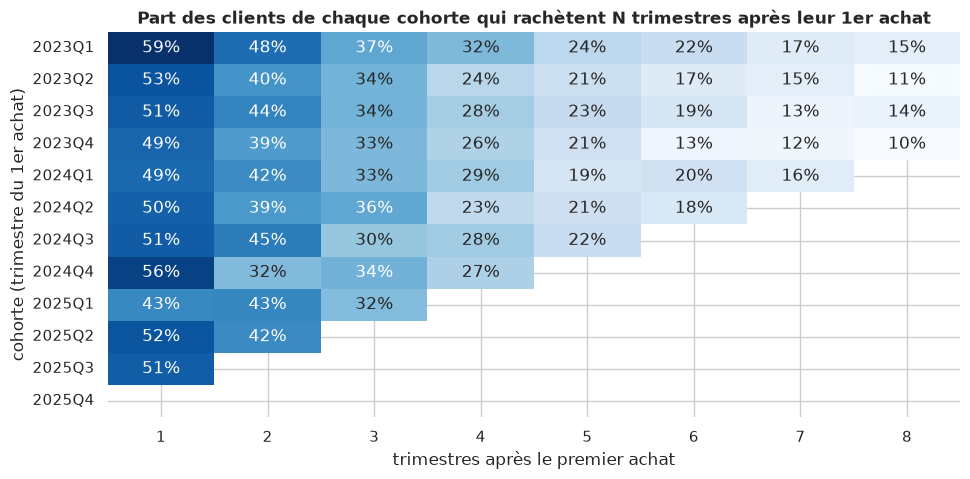

cohorte,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
clients de la cohorte,1 628.000,917.000,763.000,706.000,799.000,890.000,952.000,1 002.000,1 311.000,851.000,1 295.000,1 297.000
actifs T+1,0.592,0.527,0.510,0.492,0.486,0.499,0.508,0.558,0.428,0.522,0.505,NaN
actifs T+4,0.324,0.244,0.278,0.259,0.285,0.235,0.283,0.265,NaN,NaN,NaN,NaN


In [8]:
coh = achats[["client_sk", "date"]].copy()
coh["trimestre"] = coh["date"].dt.to_period("Q")
coh["cohorte"] = coh.groupby("client_sk")["trimestre"].transform("min")      # trimestre du 1er achat
coh["age_trim"] = (coh["trimestre"] - coh["cohorte"]).apply(lambda x: x.n)    # trimestres écoulés depuis

retention = coh.groupby(["cohorte", "age_trim"])["client_sk"].nunique().unstack()
taille = retention[0]
retention = retention.div(taille, axis=0)                                      # part de la cohorte encore active

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(retention.iloc[:, 1:9], annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Part des clients de chaque cohorte qui rachètent N trimestres après leur 1er achat")
ax.set_xlabel("trimestres après le premier achat"); ax.set_ylabel("cohorte (trimestre du 1er achat)")
montrer("Q07_1")
pd.DataFrame({"clients de la cohorte": taille, "actifs T+1": retention[1], "actifs T+4": retention.get(4)}).T

In [9]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(retention, "Q07_cohortes_retention")
print("Tableaux exportés.")

  ✔ ana.eda_q07_cohortes_retention                   12 lignes
Tableaux exportés.


> **Lecture.** Environ **la moitié** des nouveaux clients rachète le trimestre suivant (43 à 59 %), un quart après un an (24 à 32 % à T+4), et 10 à 15 % sont encore actifs deux ans après. Les cohortes se ressemblent beaucoup : la fidélité ne s'est ni améliorée ni dégradée entre 2023 et 2025. La cohorte 2023-T1 est plus grande et plus fidèle, car elle contient aussi des clients inscrits **avant 2023** (inscriptions depuis juin 2021) dont c'est le premier achat *observé*. **Pour le ML :** la chute la plus forte a lieu juste après le premier achat, ce qui confirme que la fréquence (une seule commande ou plus) est un signal clé du churn.

> ✅ **Verdict : hypothèse confirmée** — la moitié des clients seulement rachète au trimestre suivant ; les cohortes se ressemblent d'une année à l'autre.

### Q8. Où sont les clients ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Le CA est concentré sur le Grand Tunis et le Sahel ; le panier varie peu selon la région. |
| **Indicateurs** | Commandes, CA reconnu, panier moyen, part du CA par région |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_geographie`, `v_dim_statut_commande` |
| **Méthode** | SQL direct |
| **Visualisation** | Barres horizontales |
| **Lien data mining / ML** | Retard : zone de livraison |

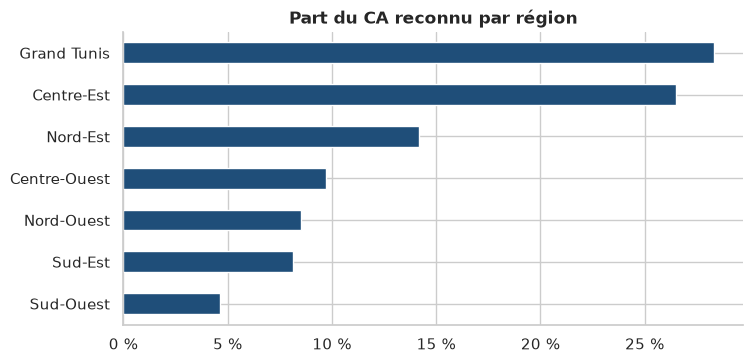

,commandes,ca_reconnu_ttc,panier_moyen_ttc,part_ca
region,,,,
Grand Tunis,16867,4 400 538.975,260.896,0.283
Centre-Est,15258,4 115 455.715,269.724,0.265
Nord-Est,7979,2 205 277.195,276.385,0.142
Centre-Ouest,5819,1 509 965.105,259.489,0.097
Nord-Ouest,5232,1 323 570.655,252.976,0.085
Sud-Est,4856,1 266 430.410,260.797,0.081
Sud-Ouest,2765,720 427.600,260.552,0.046


In [10]:
# 🔗 SQL direct — commandes reconnues et CA par région de livraison
regions = sql("""
    SELECT g.region,
           COUNT(*)                            AS commandes,
           SUM(c.montant_total_ttc)            AS ca_reconnu_ttc,
           SUM(c.montant_total_ttc) / COUNT(*) AS panier_moyen_ttc
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_geographie g       ON g.geographie_sk = c.geographie_sk
    JOIN bi.v_dim_statut_commande s  ON s.statut_commande_sk = c.statut_commande_sk
    WHERE s.famille_statut = 'aboutie' AND c.geographie_sk > 0
    GROUP BY g.region
    ORDER BY ca_reconnu_ttc DESC
""").set_index("region")
regions["part_ca"] = regions["ca_reconnu_ttc"] / regions["ca_reconnu_ttc"].sum()

ax = regions["part_ca"][::-1].plot.barh(color=cfg.BLEU, figsize=(8, 3.8))
ax.set_title("Part du CA reconnu par région"); cfg.format_pourcent(ax, "x"); ax.set_ylabel("")
montrer("Q08_1")
regions

In [11]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(regions, "Q08_regions")
print("Tableaux exportés.")

  ✔ ana.eda_q08_regions                               7 lignes
Tableaux exportés.


> **Lecture.** Deux régions font **55 % du CA** : le Grand Tunis (28 %) et le Centre-Est (27 %) ; le Sud-Ouest ne pèse que 5 %. Le panier moyen varie peu d'une région à l'autre (253 à 276 DT) : les écarts viennent du nombre de clients, pas de leur dépense. **Pour le ML :** la région influence surtout la logistique (zone de livraison, transporteur), donc le cas du retard plus que le churn.

> ✅ **Verdict : hypothèse confirmée** — Grand Tunis et Centre-Est font 55 % du CA ; le panier varie de 253 à 276 DT selon la région.

### Q15. Le retard dégrade-t-il la satisfaction ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Plus le retard est long, plus la note baisse (note ≈ 4,1 sans retard, contrôle CC19). |
| **Indicateurs** | Note moyenne par tranche de retard de la commande |
| **Vues bi utilisées** | `v_fact_avis`, `v_fact_livraisons` |
| **Méthode** | pandas |
| **Visualisation** | Barres |
| **Lien data mining / ML** | Churn : expérience de livraison |

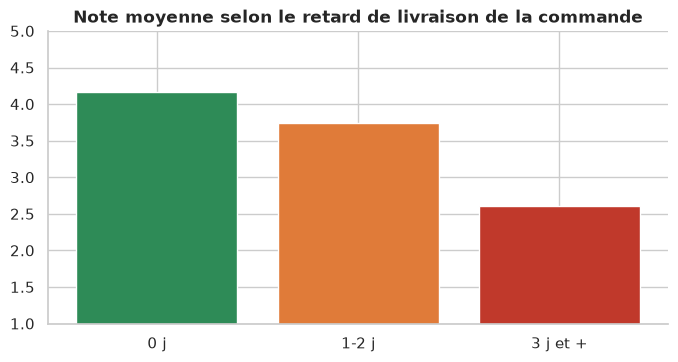

,avis,note_moyenne
tranche_retard,,
0 j,7 583.000,4.166
1-2 j,1 438.000,3.737
3 j et +,283.000,2.604
non livrée,NaN,NaN


In [12]:
note_retard = avis.groupby("tranche_retard")["note"].agg(avis="count", note_moyenne="mean")
note_retard = note_retard.reindex(["0 j", "1-2 j", "3 j et +", "non livrée"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(note_retard.index, note_retard["note_moyenne"], color=[cfg.VERT, cfg.ORANGE, cfg.ROUGE, cfg.GRIS])
ax.set_ylim(1, 5); ax.set_title("Note moyenne selon le retard de livraison de la commande")
montrer("Q15_1")
note_retard

In [13]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(note_retard, "Q15_note_selon_retard")
print("Tableaux exportés.")

  ✔ ana.eda_q15_note_selon_retard                     4 lignes
Tableaux exportés.


> **Lecture.** Le retard détruit la satisfaction : note moyenne de **4,17** sans retard, 3,74 pour 1 à 2 jours, et **2,60** au-delà de 3 jours. **Pour le ML :** les cas 1 et 2 sont liés. L'expérience de livraison vécue (`part_livraisons_retard`, `retard_max_j`, `note_moyenne`) est une piste naturelle pour expliquer le churn.

> ✅ **Verdict : hypothèse confirmée** — note 4,17 sans retard, 3,74 pour 1 à 2 jours, 2,60 au-delà.

### Q18. Que disent les avis ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Les avis sont plutôt positifs ; le sentiment est très lié à la note (risque de redondance). |
| **Indicateurs** | Nombre d'avis, note moyenne, part commentée, part négative par an ; notes par catégorie ; note × sentiment |
| **Vues bi utilisées** | `v_fact_avis`, `v_dim_produit`, `v_dim_date` |
| **Méthode** | SQL direct + pandas |
| **Visualisation** | Barres ; tableau croisé |
| **Lien data mining / ML** | Churn : note_moyenne ; retard : fuite à exclure |

,annee,avis,note_moyenne,part_commentee,part_negatifs
0,2023,2026,4.090,0.647,0.119
1,2024,2895,4.050,0.658,0.119
2,2025,4393,4.036,0.652,0.121


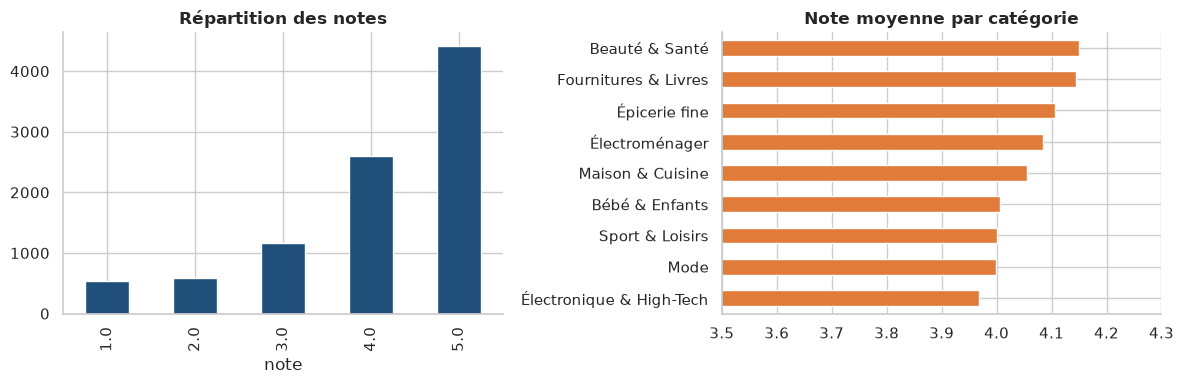

sentiment,negatif,neutre,positif
note,,,
1.000,532,0,0
2.000,588,0,0
3.000,0,1160,0
4.000,0,0,2604
5.000,0,0,4420


In [14]:
# 🔗 SQL direct — avis par année : nombre, note moyenne, part avec commentaire
display(sql("""
    SELECT d.annee,
           COUNT(*)                                                             AS avis,
           AVG(1.0 * a.note)                                                    AS note_moyenne,
           1.0 * SUM(CASE WHEN a.a_commentaire = 1 THEN 1 ELSE 0 END) / COUNT(*) AS part_commentee,
           1.0 * SUM(CASE WHEN a.note <= 2 THEN 1 ELSE 0 END) / COUNT(*)         AS part_negatifs
    FROM bi.v_fact_avis a
    JOIN bi.v_dim_date d ON d.date_sk = a.date_avis_sk
    GROUP BY d.annee
    ORDER BY d.annee
"""))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
avis["note"].value_counts().sort_index().plot.bar(ax=axes[0], color=cfg.BLEU)
axes[0].set_title("Répartition des notes"); axes[0].set_xlabel("note")
avis.groupby("categorie")["note"].mean().sort_values().plot.barh(ax=axes[1], color=cfg.ORANGE)
axes[1].set_xlim(3.5, 4.3); axes[1].set_title("Note moyenne par catégorie"); axes[1].set_ylabel("")
plt.tight_layout(); montrer("Q18_1")

# Le sentiment est-il une information différente de la note ?
pd.crosstab(avis["note"], avis["sentiment"])

> **Lecture.** Les avis sont plutôt positifs (47 % de notes 5, 12 % de notes 1 ou 2) et la note baisse légèrement chaque année (4,09 → 4,04), en même temps que les retards augmentent. Les écarts entre catégories sont faibles (3,97 pour l'Électronique à 4,15 pour la Beauté). Deux personnes sur trois laissent un commentaire. Le tableau croisé montre que le **sentiment est calculé à partir de la note** (1-2 = négatif, 3 = neutre, 4-5 = positif) : il n'apporte aucune information de plus. **Pour le ML :** ne jamais utiliser note et sentiment ensemble, et ne jamais les utiliser pour prédire le retard (ils sont donnés après la livraison : fuite de données).

> ✅ **Verdict : hypothèse confirmée** — 47 % de notes 5 ; le sentiment est exactement déduit de la note.

## Synthèse du notebook

| N° | Question | Verdict | Constat clé |
|---|---|---|---|
| Q5 | Combien de fois les clients achètent-ils ? D'où viennent les clients de l'année ? | ✅ Confirmée | la moitié des clients a 3 commandes ou moins ; 64 à 66 % des clients de l'année sont nouveaux. |
| Q6 | Le profil du client (type, âge, canal d'inscription) change-t-il sa valeur ? | ✅ Confirmée | un professionnel vaut près de 5 particuliers ; le canal d'inscription crée 25 % d'écart ; l'âge très peu. |
| Q7 | Les clients reviennent-ils ? (analyse de cohortes) | ✅ Confirmée | la moitié des clients seulement rachète au trimestre suivant ; les cohortes se ressemblent d'une année à l'autre. |
| Q8 | Où sont les clients ? | ✅ Confirmée | Grand Tunis et Centre-Est font 55 % du CA ; le panier varie de 253 à 276 DT selon la région. |
| Q15 | Le retard dégrade-t-il la satisfaction ? | ✅ Confirmée | note 4,17 sans retard, 3,74 pour 1 à 2 jours, 2,60 au-delà. |
| Q18 | Que disent les avis ? | ✅ Confirmée | 47 % de notes 5 ; le sentiment est exactement déduit de la note. |

**Ce que ce notebook transmet à la suite :**

- **RFM et clustering** : distributions très asymétriques (montants) → logarithme ou scores par quantiles.
- **Churn** : la récence et la fréquence seront centrales ; `type_client` et `canal_inscription` sont utiles, `tranche_age` faible ; l'expérience de livraison (retard, note) pèse sur la satisfaction.
- **Fuite** : note et sentiment sont redondants et connus après la livraison.

In [15]:
# Verdicts des hypothèses de ce notebook, enregistrés comme les autres résultats :
#   -> 06_Exports/Tables/EDA_hypotheses_03_EDA_Customers.csv
#   -> table ana.eda_hypotheses de TuniShop_ANALYTICS (lignes de ce notebook seulement, colonne « notebook »)
verdicts = pd.DataFrame([["Q5", "Clients", "Combien de fois les clients achètent-ils ? D'où viennent les clients de l'année ?", "La plupart des clients achètent peu ; une grande part des clients de l'année sont nouveaux.", "Confirmée", "la moitié des clients a 3 commandes ou moins ; 64 à 66 % des clients de l'année sont nouveaux."], ["Q6", "Clients", "Le profil du client (type, âge, canal d'inscription) change-t-il sa valeur ?", "Le type de client et le canal d'inscription influencent la valeur ; l'âge influence peu.", "Confirmée", "un professionnel vaut près de 5 particuliers ; le canal d'inscription crée 25 % d'écart ; l'âge très peu."], ["Q7", "Clients", "Les clients reviennent-ils ? (analyse de cohortes)", "La perte de clients est la plus forte juste après le premier achat ; la fidélité est stable dans le temps.", "Confirmée", "la moitié des clients seulement rachète au trimestre suivant ; les cohortes se ressemblent d'une année à l'autre."], ["Q8", "Clients", "Où sont les clients ?", "Le CA est concentré sur le Grand Tunis et le Sahel ; le panier varie peu selon la région.", "Confirmée", "Grand Tunis et Centre-Est font 55 % du CA ; le panier varie de 253 à 276 DT selon la région."], ["Q15", "Livraison et satisfaction", "Le retard dégrade-t-il la satisfaction ?", "Plus le retard est long, plus la note baisse (note ≈ 4,1 sans retard, contrôle CC19).", "Confirmée", "note 4,17 sans retard, 3,74 pour 1 à 2 jours, 2,60 au-delà."], ["Q18", "Retours, remboursements et avis", "Que disent les avis ?", "Les avis sont plutôt positifs ; le sentiment est très lié à la note (risque de redondance).", "Confirmée", "47 % de notes 5 ; le sentiment est exactement déduit de la note."]],
                        columns=["question", "theme", "question_metier", "hypothese", "verdict", "constat"])
cfg.exporter_table(verdicts, "EDA_hypotheses_03_EDA_Customers", index=False)
verdicts[["question", "verdict"]]

  ✔ ana.eda_hypotheses                                6 lignes


,question,verdict
0,Q5,Confirmée
1,Q6,Confirmée
2,Q7,Confirmée
3,Q8,Confirmée
4,Q15,Confirmée
5,Q18,Confirmée


In [16]:
# Fin du notebook : on ferme les connexions (DWH et base des résultats)
chargement.fermer_connexion()
publication.fermer_connexion()

Connexion fermée.
